In [95]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 5GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [96]:
import matplotlib.pyplot as plt
import seaborn as sns

Importing the data

In [97]:
data=pd.read_csv("student-por.csv",sep=",")


In [98]:
data.head(10)

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13
5,GP,M,16,U,LE3,T,4,3,services,other,...,5,4,2,1,2,5,6,12,12,13
6,GP,M,16,U,LE3,T,2,2,other,other,...,4,4,4,1,1,3,0,13,12,13
7,GP,F,17,U,GT3,A,4,4,other,teacher,...,4,1,4,1,1,1,2,10,13,13
8,GP,M,15,U,LE3,A,3,2,services,other,...,4,2,2,1,1,1,0,15,16,17
9,GP,M,15,U,GT3,T,3,4,other,other,...,5,5,1,1,1,5,0,12,12,13


Merging two datasets

In [99]:
data["avg_grades"]=(data["G1"]+data["G2"]+data["G3"])/3

Dropping columns

In [100]:
data=data.drop(["G1","G2","G3"],axis=1)
max=data["avg_grades"].max()
min=data["avg_grades"].min()

In [101]:
def marks(avg_grades):
    if avg_grades < 7:
        return "low"
    elif avg_grades < 10:
        return "below average"
    elif avg_grades < 14:
        return "average"
    elif avg_grades < 17:
        return "above average"
    else:
        return "high"

data["grades"] = data["avg_grades"].apply(marks)

data["grades"].value_counts()


grades
average          355
below average    135
above average    111
high              26
low               22
Name: count, dtype: int64

ANALYZING THE DATA

In [102]:
data.dtypes
data.describe()


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,avg_grades
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,2.514638,2.306626,1.568567,1.930663,0.221880,3.930663,3.180277,3.184900,1.502311,2.280431,3.536210,3.659476,11.625064
std,1.218138,1.134552,1.099931,0.748660,0.829510,0.593235,0.955717,1.051093,1.175766,0.924834,1.284380,1.446259,4.640759,2.833360
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.333333
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000,10.000000
50%,17.000000,2.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.666667
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.333333
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,32.000000,18.666667


In [103]:
#describing categorical data
data.describe(include="all")


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,avg_grades,grades
count,649,649,649.000000,649,649,649,649.000000,649.000000,649,649,...,649,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649
unique,2,2,NaN,2,2,2,NaN,NaN,5,5,...,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5
top,GP,F,NaN,U,GT3,T,NaN,NaN,other,other,...,no,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,average
freq,423,383,NaN,452,457,569,NaN,NaN,258,367,...,410,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,355
mean,NaN,NaN,16.744222,NaN,NaN,NaN,2.514638,2.306626,NaN,NaN,...,NaN,3.930663,3.180277,3.184900,1.502311,2.280431,3.536210,3.659476,11.625064,NaN
std,NaN,NaN,1.218138,NaN,NaN,NaN,1.134552,1.099931,NaN,NaN,...,NaN,0.955717,1.051093,1.175766,0.924834,1.284380,1.446259,4.640759,2.833360,NaN
min,NaN,NaN,15.000000,NaN,NaN,NaN,0.000000,0.000000,NaN,NaN,...,NaN,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.333333,NaN
25%,NaN,NaN,16.000000,NaN,NaN,NaN,2.000000,1.000000,NaN,NaN,...,NaN,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000,10.000000,NaN
50%,NaN,NaN,17.000000,NaN,NaN,NaN,2.000000,2.000000,NaN,NaN,...,NaN,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.666667,NaN
75%,NaN,NaN,18.000000,NaN,NaN,NaN,4.000000,3.000000,NaN,NaN,...,NaN,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.333333,NaN


In [104]:
data.info()

#checking for null values
data.isnull().any()

<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 32 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   school      649 non-null    str    
 1   sex         649 non-null    str    
 2   age         649 non-null    int64  
 3   address     649 non-null    str    
 4   famsize     649 non-null    str    
 5   Pstatus     649 non-null    str    
 6   Medu        649 non-null    int64  
 7   Fedu        649 non-null    int64  
 8   Mjob        649 non-null    str    
 9   Fjob        649 non-null    str    
 10  reason      649 non-null    str    
 11  guardian    649 non-null    str    
 12  traveltime  649 non-null    int64  
 13  studytime   649 non-null    int64  
 14  failures    649 non-null    int64  
 15  schoolsup   649 non-null    str    
 16  famsup      649 non-null    str    
 17  paid        649 non-null    str    
 18  activities  649 non-null    str    
 19  nursery     649 non-null    str    
 20 

school        False
sex           False
age           False
address       False
famsize       False
Pstatus       False
Medu          False
Fedu          False
Mjob          False
Fjob          False
reason        False
guardian      False
traveltime    False
studytime     False
failures      False
schoolsup     False
famsup        False
paid          False
activities    False
nursery       False
higher        False
internet      False
romantic      False
famrel        False
freetime      False
goout         False
Dalc          False
Walc          False
health        False
absences      False
avg_grades    False
grades        False
dtype: bool

Text(0, 0.5, 'Number of datadent')

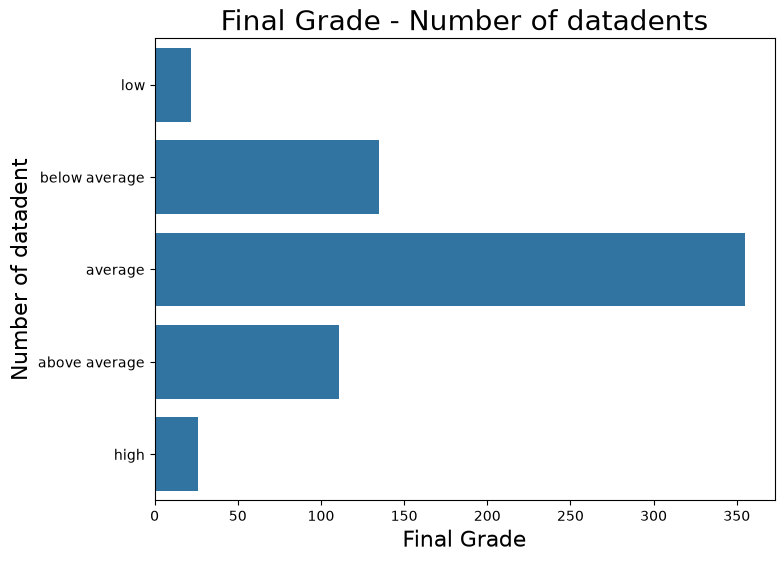

In [105]:
#visualizing the grades
plt.figure(figsize=(8,6))
sns.countplot(data["grades"], order=["low","below average","average","above average","high"])
plt.title('Final Grade - Number of datadents',fontsize=20)
plt.xlabel('Final Grade', fontsize=16)
plt.ylabel('Number of datadent', fontsize=16)

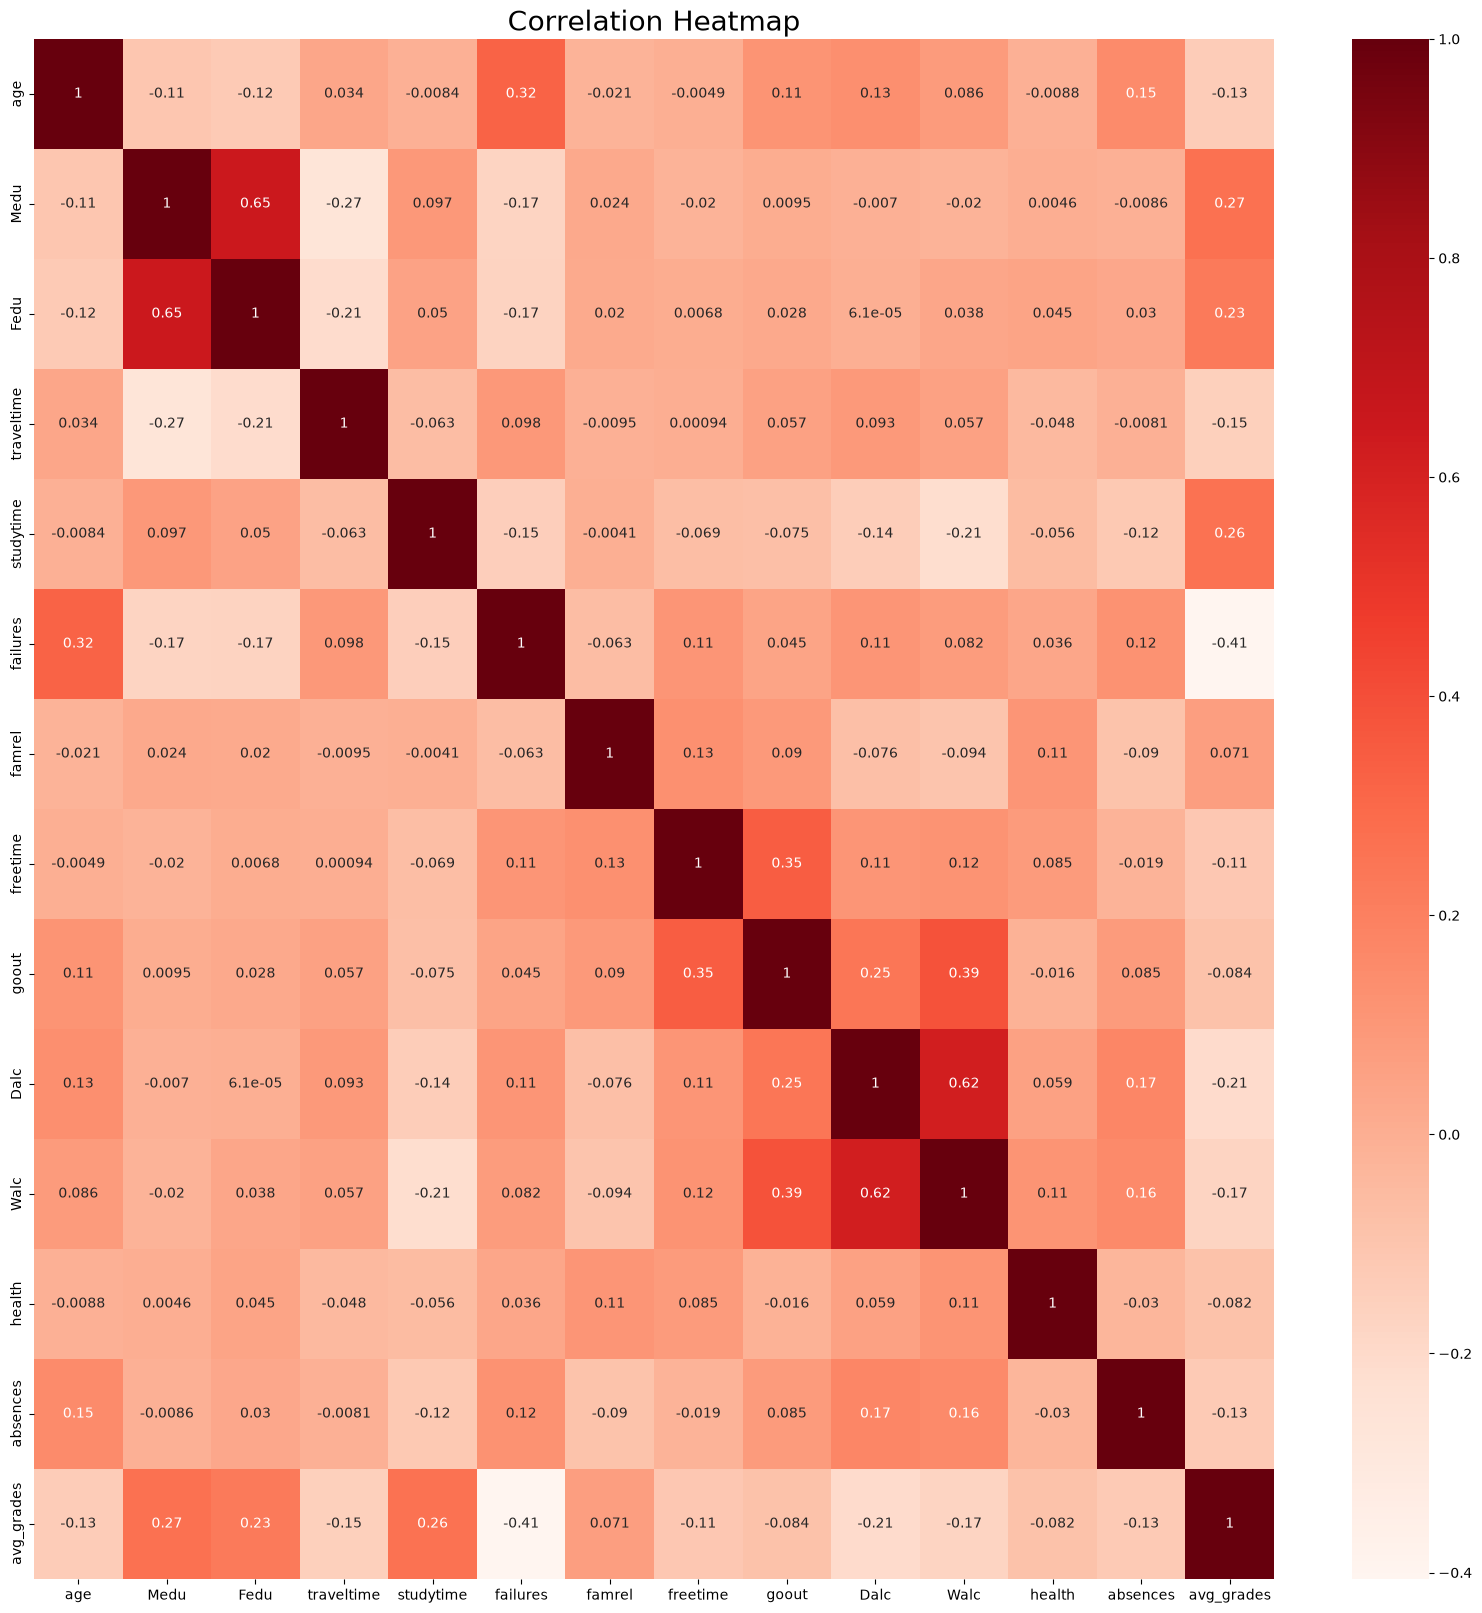

In [106]:
#describing correlation
# data["GP"].head()

# Correlation applies to numeric columns only
corr = data.select_dtypes(include="number").corr()

plt.figure(figsize=(20, 20))
sns.heatmap(corr, annot=True, cmap="Reds")
plt.title("Correlation Heatmap", fontsize=20)
plt.show()

ANALYZING CATEGORICAL VARIABLES

using boxplots

C:\Users\joche\AppData\Local\Temp\ipykernel_9352\1673533612.py:5: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  school_counts.rename(columns={"school":"school_counts"},inplace=True)


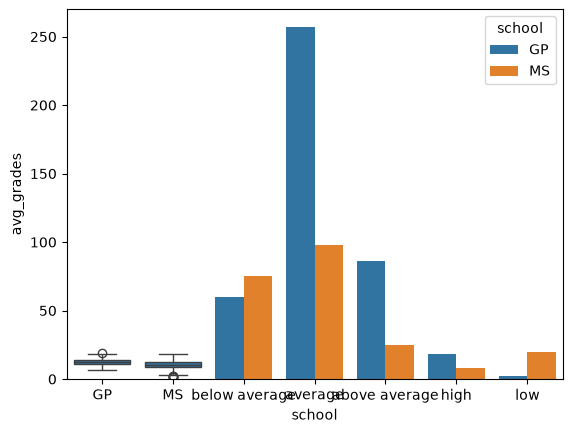

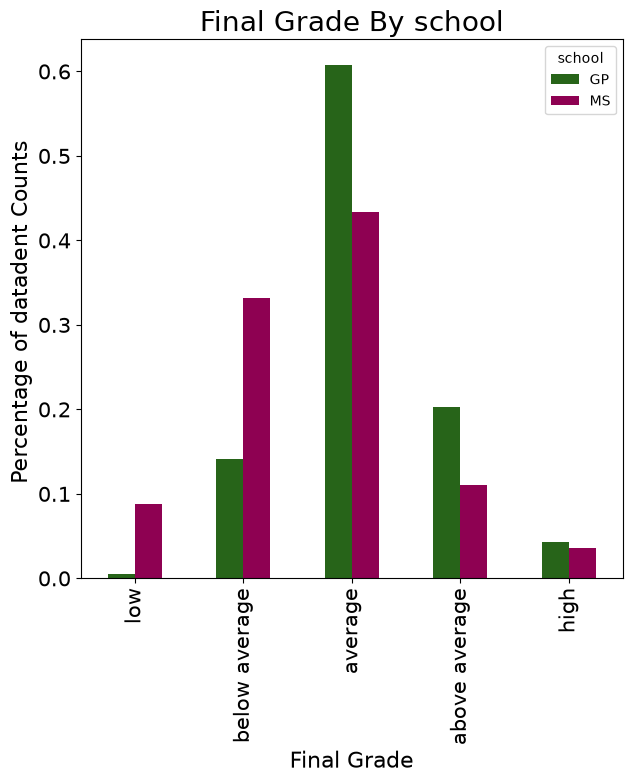

In [107]:
#comparing school with grades
sns.boxplot(x="school", y="avg_grades", data=data)

school_counts=data["school"].value_counts().to_frame()
school_counts.rename(columns={"school":"school_counts"},inplace=True)
school_counts.index.name='school'

school_sns=sns.countplot(hue=data["school"],x=data["grades"],data=data)

#crosstab is expanded form of value counts the the factors inside any variables
perc=(lambda col:col/col.sum())
index=["low","below average","average","above average","high"]
schooltab1=pd.crosstab(columns=data.school,index=data.grades)

school_perc=schooltab1.apply(perc).reindex(index)

school_perc.plot.bar(colormap="PiYG_r",fontsize=15,figsize=(7,7))
plt.title('Final Grade By school', fontsize=20)
plt.ylabel('Percentage of datadent Counts ', fontsize=16)
plt.xlabel('Final Grade', fontsize=16)
plt.show()

#so by graph we know that school has impact on grades of datadents

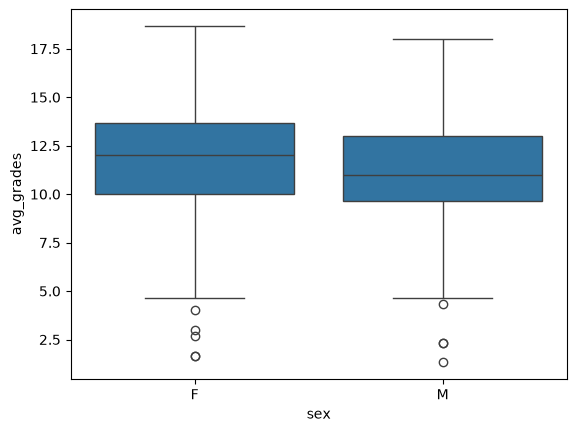

In [108]:
#comparing sex with grades
sns.boxplot(x="sex", y="avg_grades", data=data)
school_counts=data["sex"].value_counts()
#as the graph of sex nearly overlaps so it will not have impact on grades
data=data.drop(["sex"],axis=1)



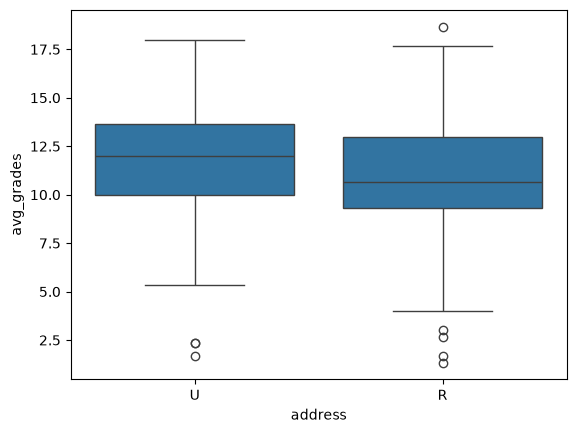

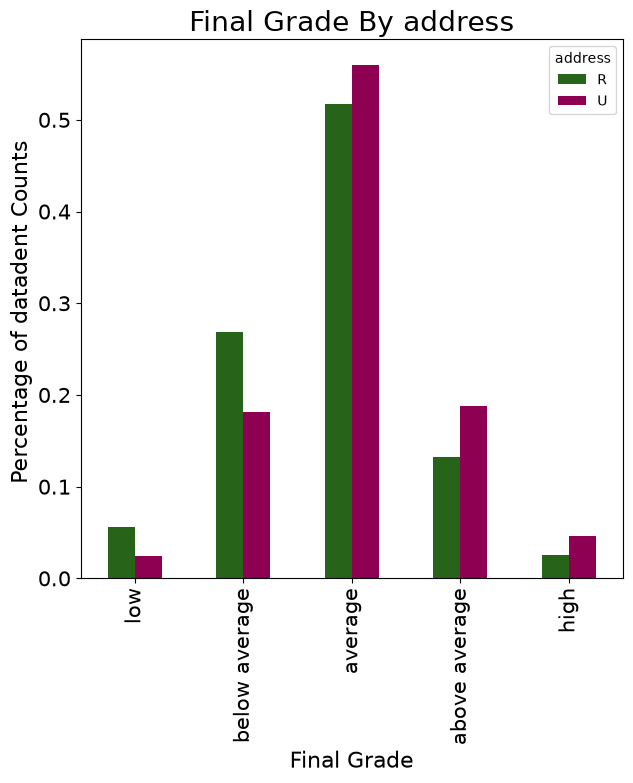

In [109]:
#comparing address with grades
sns.boxplot(x="address", y="avg_grades", data=data)
index=["low","below average","average","above average","high"]
addresstab1=pd.crosstab(columns=data.address,index=data.grades)

address_perc=addresstab1.apply(perc).reindex(index)

address_perc.plot.bar(colormap="PiYG_r",fontsize=15,figsize=(7,7))
plt.title('Final Grade By address', fontsize=20)
plt.ylabel('Percentage of datadent Counts ', fontsize=16)
plt.xlabel('Final Grade', fontsize=16)
plt.show()
#address is factor for the grades

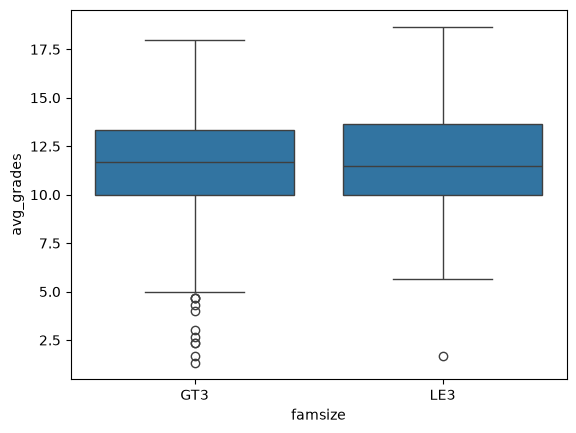

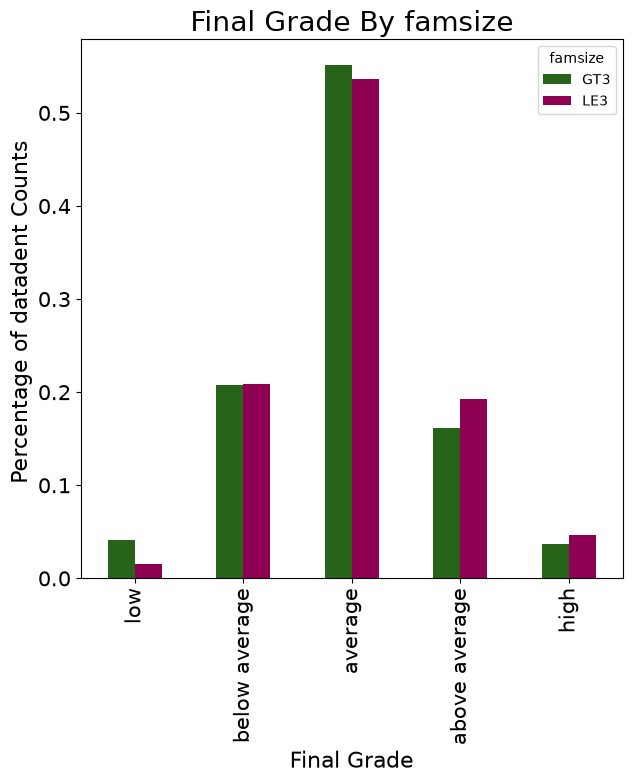

In [110]:
#comparing famsize with grades
sns.boxplot(x="famsize", y="avg_grades", data=data)
famsizetab1=pd.crosstab(columns=data.famsize,index=data.grades)

famsize_perc=famsizetab1.apply(perc).reindex(index)

famsize_perc.plot.bar(colormap="PiYG_r",fontsize=15,figsize=(7,7))
plt.title('Final Grade By famsize', fontsize=20)
plt.ylabel('Percentage of datadent Counts ', fontsize=16)
plt.xlabel('Final Grade', fontsize=16)
plt.show()
#famsize has great impact on grades

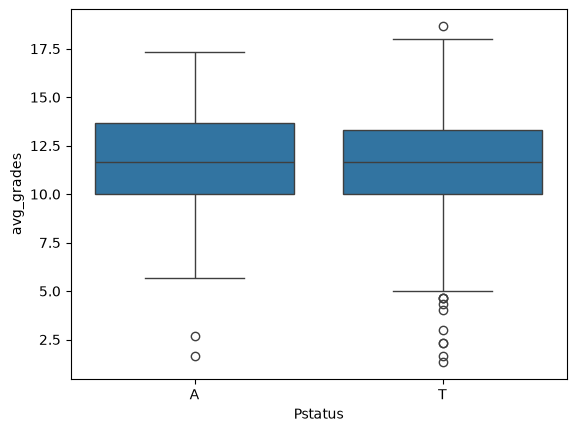

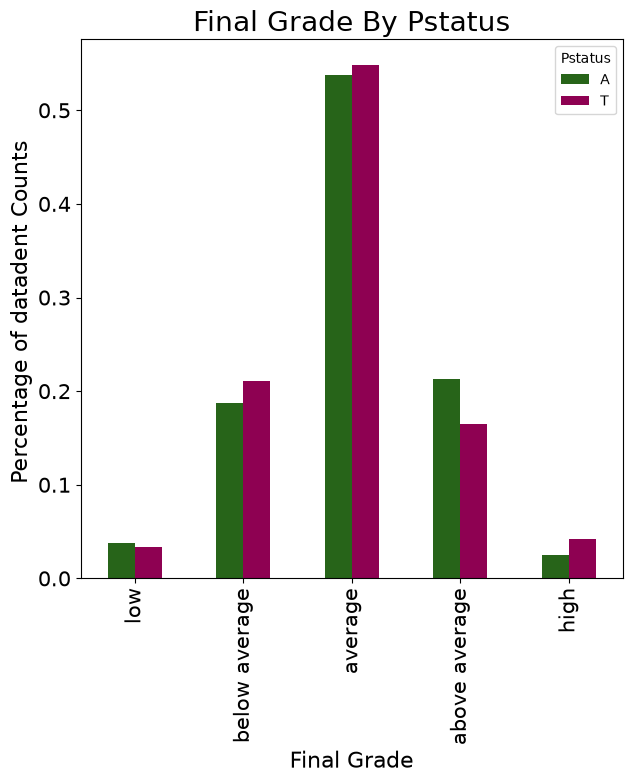

In [111]:
#comparing pstatus with grades
sns.boxplot(x="Pstatus", y="avg_grades", data=data)
Pstatustab1=pd.crosstab(columns=data.Pstatus,index=data.grades)

Pstatus_perc=Pstatustab1.apply(perc).reindex(index)

Pstatus_perc.plot.bar(colormap="PiYG_r",fontsize=15,figsize=(7,7))
plt.title('Final Grade By Pstatus', fontsize=20)
plt.ylabel('Percentage of datadent Counts ', fontsize=16)
plt.xlabel('Final Grade', fontsize=16)
plt.show()
#it is not a good factor

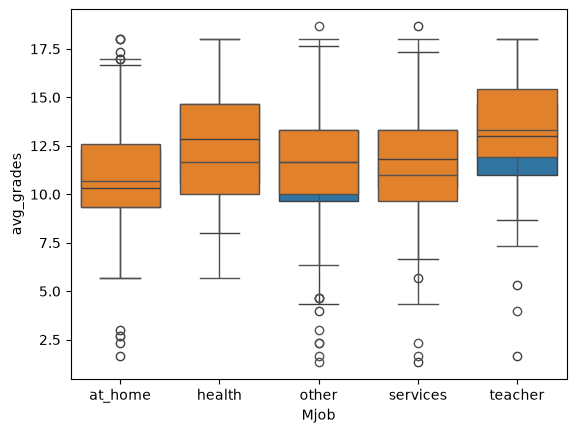

In [112]:
#comparing jobs
sns.boxplot(x="Mjob", y="avg_grades", data=data)
sns.boxplot(x="Fjob", y="avg_grades", data=data)
data1=data[["Fjob","Mjob","avg_grades"]]
job_grp=data1.groupby(['Mjob','Fjob'],as_index=False).mean()
job_pivot=job_grp.pivot(index='Mjob',columns='Fjob',values='avg_grades')

#so father and mother jobs has great impact on grades

<Axes: xlabel='reason', ylabel='avg_grades'>

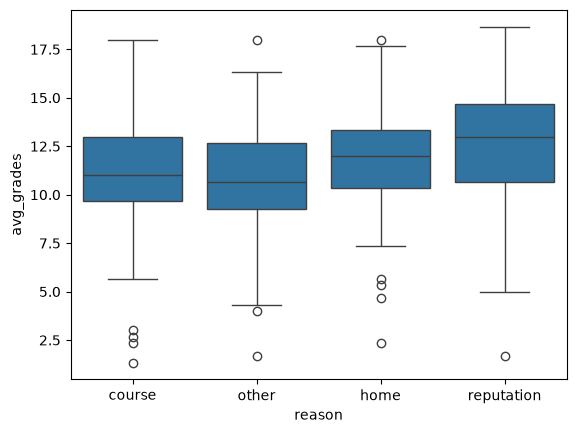

In [113]:
#comparing reasons
sns.boxplot(x="reason", y="avg_grades", data=data)
#it has impact on the grades

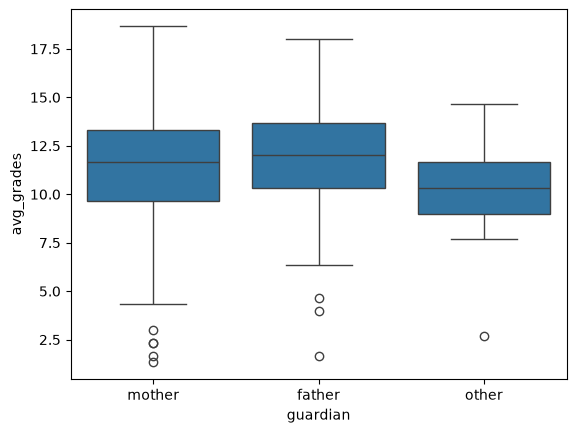

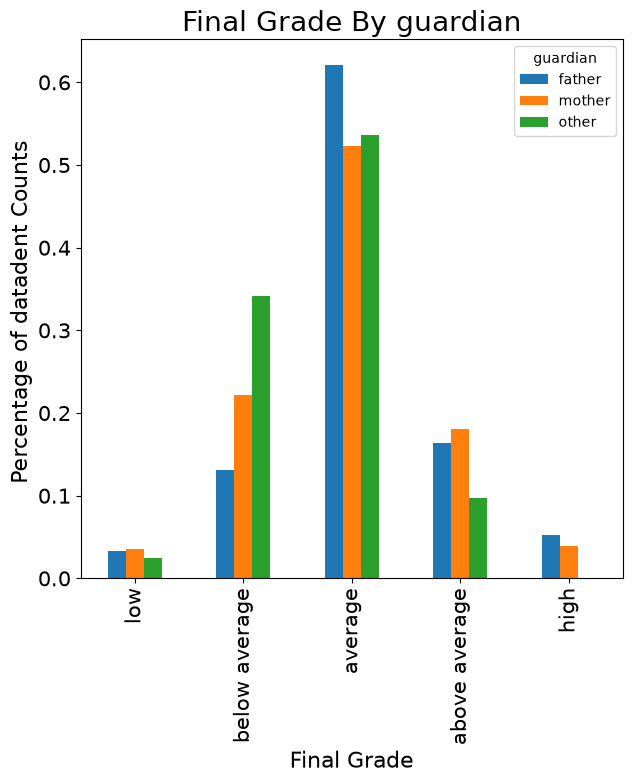

In [114]:
#comparing guardians
sns.boxplot(x="guardian", y="avg_grades", data=data)

guardiantab1=pd.crosstab(columns=data.guardian,index=data.grades)
guardian_perc=guardiantab1.apply(perc).reindex(index)
guardian_perc.plot.bar(fontsize=15,figsize=(7,7))
plt.title('Final Grade By guardian', fontsize=20)
plt.ylabel('Percentage of datadent Counts ', fontsize=16)
plt.xlabel('Final Grade', fontsize=16)
plt.show()
#so guardian has grat impact on grades

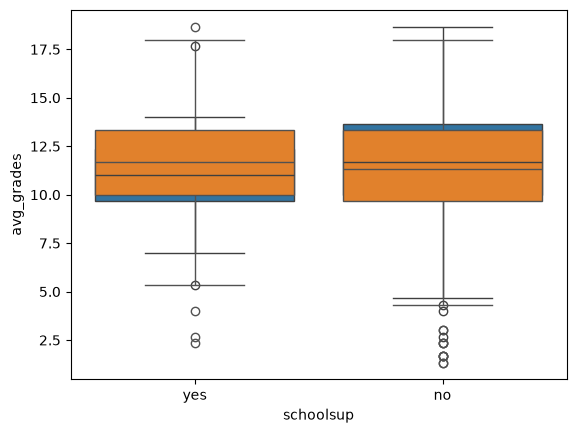

In [115]:
#support of family and school
sns.boxplot(x="schoolsup", y="avg_grades", data=data)
#it is the important factor
sns.boxplot(x="famsup", y="avg_grades", data=data)
data[["famsup","avg_grades"]].groupby(["famsup"],as_index=False).mean()
#famsup does not have great impact on grades 
data=data.drop(["famsup"],axis=1) 

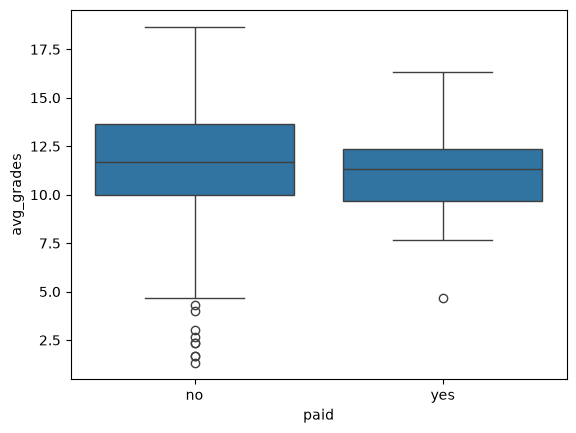

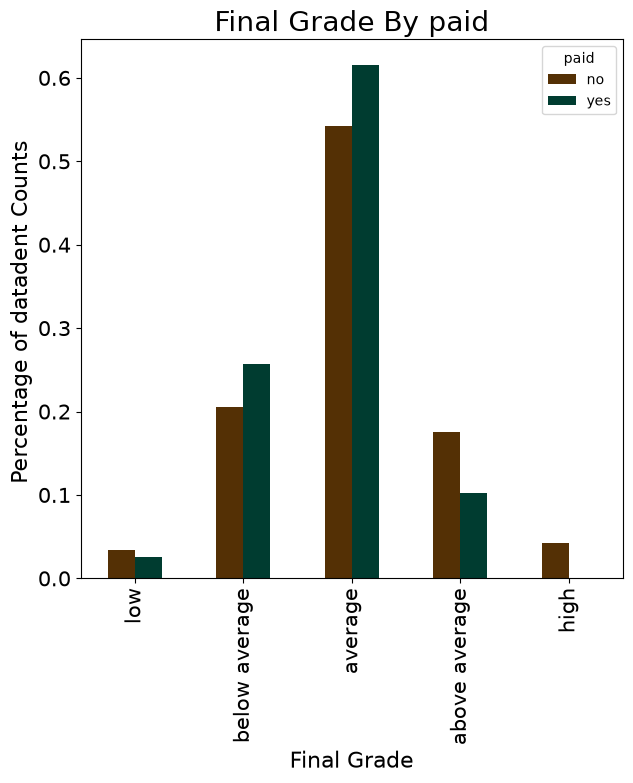

In [116]:
#comparing paid attributes
sns.boxplot(x="paid", y="avg_grades", data=data)
paidtab1=pd.crosstab(columns=data.paid,index=data.grades)
paid_perc=paidtab1.apply(perc).reindex(index)
paid_perc.plot.bar(colormap="BrBG",fontsize=15,figsize=(7,7))
plt.title('Final Grade By paid', fontsize=20)
plt.ylabel('Percentage of datadent Counts ', fontsize=16)
plt.xlabel('Final Grade', fontsize=16)
plt.show()
#paid does not have much influence on grades so
data=data.drop(["paid"],axis=1)




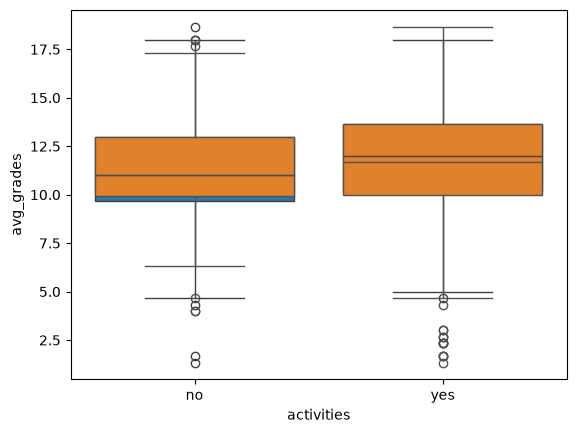

In [117]:
sns.boxplot(x="activities", y="avg_grades", data=data)
#is has graet impact on datadent perforamnce
sns.boxplot(x="nursery", y="avg_grades", data=data)
#it does not have great impact on performance
data=data.drop(["nursery"],axis=1)

<Axes: xlabel='higher', ylabel='avg_grades'>

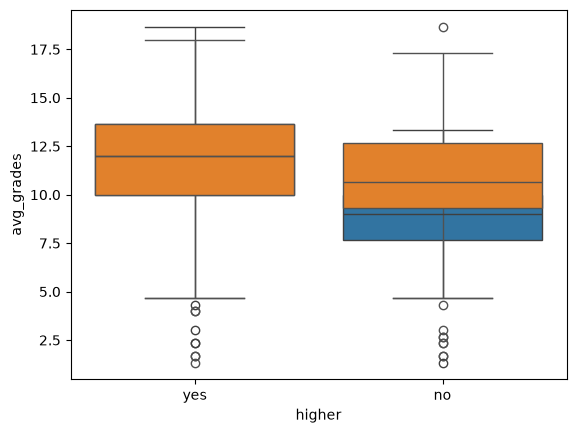

In [118]:
#comparing if higher educatiob of datadents have impact on performance
sns.boxplot(x="higher", y="avg_grades", data=data)

sns.boxplot(x="internet", y="avg_grades", data=data)
#internet also have great impact on performance of individual


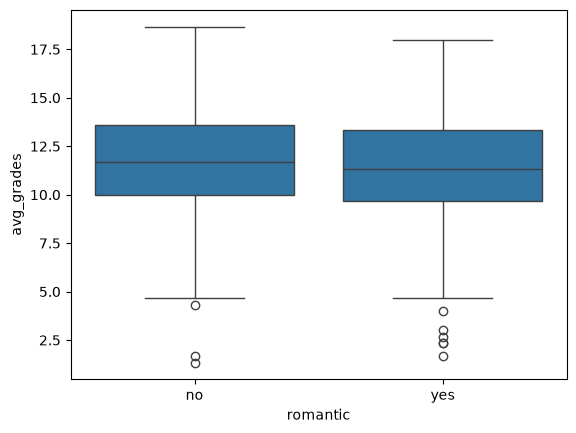

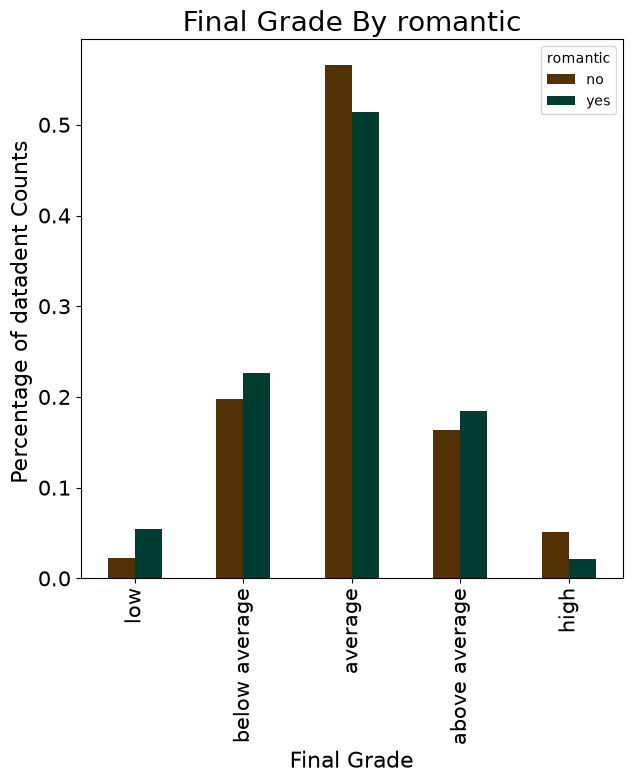

In [119]:
#high school romace impact on the performance of datadents
sns.boxplot(x="romantic", y="avg_grades", data=data)
romantictab1=pd.crosstab(columns=data.romantic,index=data.grades)
romantic_perc=romantictab1.apply(perc).reindex(index)
romantic_perc.plot.bar(colormap="BrBG",fontsize=15,figsize=(7,7))
plt.title('Final Grade By romantic', fontsize=20)
plt.ylabel('Percentage of datadent Counts ', fontsize=16)
plt.xlabel('Final Grade', fontsize=16)
plt.show()
#so high school romance leads to decline in performance of datadents
#beware of that

#encoding categorical data

In [120]:
data.columns

Index(['school', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'activities', 'higher', 'internet', 'romantic',
       'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences',
       'avg_grades', 'grades'],
      dtype='str')

In [121]:
data1=pd.get_dummies(data,columns=["school","address","famsize","Pstatus","Mjob","Fjob","reason","guardian", 'schoolsup', 'activities', 'higher', 'internet', 'romantic' ])
test_data1=data1["grades"]
testdata1=data1["avg_grades"]
train_data1=data1.drop(['avg_grades','grades'],axis=1)
train_data=train_data1.values

In [122]:
train_data1

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,schoolsup_no,schoolsup_yes,activities_no,activities_yes,higher_no,higher_yes,internet_no,internet_yes,romantic_no,romantic_yes
0,18,4,4,2,2,0,4,3,4,1,...,False,True,True,False,False,True,True,False,True,False
1,17,1,1,1,2,0,5,3,3,1,...,True,False,True,False,False,True,False,True,True,False
2,15,1,1,1,2,0,4,3,2,2,...,False,True,True,False,False,True,False,True,True,False
3,15,4,2,1,3,0,3,2,2,1,...,True,False,False,True,False,True,False,True,False,True
4,16,3,3,1,2,0,4,3,2,1,...,True,False,True,False,False,True,True,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
644,19,2,3,1,3,1,5,4,2,1,...,True,False,False,True,False,True,False,True,True,False
645,18,3,1,1,2,0,4,3,4,1,...,True,False,True,False,False,True,False,True,True,False
646,18,1,1,2,2,0,1,1,1,1,...,True,False,False,True,False,True,True,False,True,False
647,17,3,1,2,1,0,2,4,5,3,...,True,False,True,False,False,True,False,True,True,False


In [123]:
testdata1

0       7.333333
1      10.333333
2      12.333333
3      14.000000
4      12.333333
         ...    
644    10.333333
645    15.333333
646    10.666667
647    10.000000
648    10.666667
Name: avg_grades, Length: 649, dtype: float64

ANALYZING NUMERICAL VARIABLES

<Axes: xlabel='age', ylabel='avg_grades'>

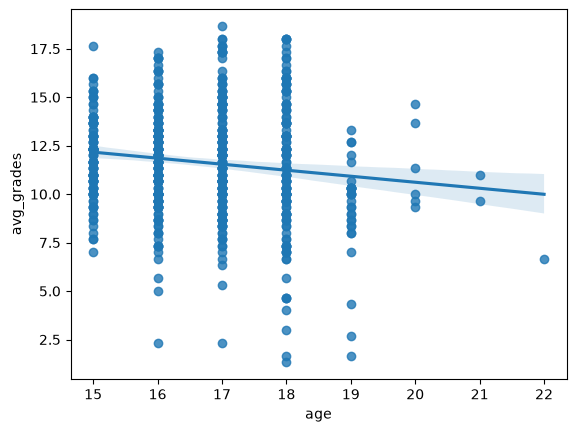

In [124]:
from scipy import stats
#comparing age with marks
sns.regplot(x="age",y="avg_grades",data=data)



In [125]:
#pearson coeffiecient
data[["age","avg_grades"]].corr()
#p-value
pearson_coef , p_value=stats.pearsonr(data["age"],data["avg_grades"])
print("The Pearson Correlation Coefficient is", pearson_coef, " with a P-value of P =", p_value)
#age is not a good factor

The Pearson Correlation Coefficient is -0.13349865498491353  with a P-value of P = 0.0006504408411429226


In [126]:
#using backward elimination for finding optimal featrures

#if p-value is greater than 0.6 than we will removethat feature
import statsmodels.api as sm
X=np.append(arr=np.ones((649,1)).astype(int),values=train_data,axis=1)
X_opt = X[:, [0, 1, 2, 3, 4,5,6,7,8,9,10,11,12,13]]
regressor_ols=sm.OLS(endog=testdata1,exog=X_opt).fit()
regressor_ols.summary()

X_opt = X[:, [0,2,3,4,5,6,7,8,9,10,11,12,13]]
regressor_ols=sm.OLS(endog=testdata1,exog=X_opt).fit()
regressor_ols.summary()

X_opt = X[:, [0,2,3,4,5,6,7,9,10,11,12,13]]
regressor_ols=sm.OLS(endog=testdata1,exog=X_opt).fit()
regressor_ols.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:             avg_grades   R-squared:                       0.273
Model:                            OLS   Adj. R-squared:                  0.261
Method:                 Least Squares   F-statistic:                     21.80
Date:                Mon, 02 Nov 2026   Prob (F-statistic):           7.15e-38
Time:                        14:33:25   Log-Likelihood:                -1492.6
No. Observations:                 649   AIC:                             3009.
Df Residuals:                     637   BIC:                             3063.
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         10.7306      0.686     15.632      0.000       9.383      12.079
x1             0.3267      0.113      2.884      0.004       0.104       0.549
x2             0.1971      0.115      1.710      0.088      -0.029       0.423
x3            -0.1861      0.134     -1.390      0.165      -0.449       0.077
x4             0.5694      0.120      4.743      0.000       0.334       0.805
x5            -1.5122      0.168     -9.015      0.000      -1.842      -1.183
x6             0.1260      0.103      1.224      0.222      -0.076       0.328
x7            -0.0660      0.090     -0.737      0.462      -0.242       0.110
x8            -0.3603      0.133     -2.713      0.007      -0.621      -0.099
x9            -0.0180      0.103     -0.176      0.860      -0.219       0.183
x10           -0.1305      0.068     -1.929      0.054      -0.263       0.002
x11           -0.0258      0.021     -1.211      0.226      -0.068       0.016
==============================================================================
Omnibus:                       29.065   Durbin-Watson:                   1.763
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               49.662
Skew:                          -0.325   Prob(JB):                     1.64e-11
Kurtosis:                       4.189   Cond. No.                         66.6
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [127]:
data.describe()


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,avg_grades
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,2.514638,2.306626,1.568567,1.930663,0.221880,3.930663,3.180277,3.184900,1.502311,2.280431,3.536210,3.659476,11.625064
std,1.218138,1.134552,1.099931,0.748660,0.829510,0.593235,0.955717,1.051093,1.175766,0.924834,1.284380,1.446259,4.640759,2.833360
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.333333
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000,10.000000
50%,17.000000,2.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.666667
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.333333
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,32.000000,18.666667


In [128]:
data.columns


Index(['school', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'activities', 'higher', 'internet', 'romantic',
       'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences',
       'avg_grades', 'grades'],
      dtype='str')

In [129]:
#now we merge our training data
train_x=np.concatenate((X_opt,X[:,14:49]),axis=1)
data[["Medu","avg_grades"]].corr()
data[["Fedu","avg_grades"]].corr()

,Fedu,avg_grades
Fedu,1.000000,0.227918
avg_grades,0.227918,1.000000


In [130]:
train_data2=train_data1.drop(["age","freetime"],axis=1)
np1=[1 for i in range(0,649)]
train_data2.insert(loc=0,column= "noimprotance", value=np1)
#now after getting the proper features we will split the data


In [131]:
train_data2.columns
train_data2.head(30)

,noimprotance,Medu,Fedu,traveltime,studytime,failures,famrel,goout,Dalc,Walc,...,schoolsup_no,schoolsup_yes,activities_no,activities_yes,higher_no,higher_yes,internet_no,internet_yes,romantic_no,romantic_yes
0,1,4,4,2,2,0,4,4,1,1,...,False,True,True,False,False,True,True,False,True,False
1,1,1,1,1,2,0,5,3,1,1,...,True,False,True,False,False,True,False,True,True,False
2,1,1,1,1,2,0,4,2,2,3,...,False,True,True,False,False,True,False,True,True,False
3,1,4,2,1,3,0,3,2,1,1,...,True,False,False,True,False,True,False,True,False,True
4,1,3,3,1,2,0,4,2,1,2,...,True,False,True,False,False,True,True,False,True,False
5,1,4,3,1,2,0,5,2,1,2,...,True,False,False,True,False,True,False,True,True,False
6,1,2,2,1,2,0,4,4,1,1,...,True,False,True,False,False,True,False,True,True,False
7,1,4,4,2,2,0,4,4,1,1,...,False,True,True,False,False,True,True,False,True,False
8,1,3,2,1,2,0,4,2,1,1,...,True,False,True,False,False,True,False,True,True,False
9,1,3,4,1,2,0,5,1,1,1,...,True,False,False,True,False,True,False,True,True,False


Splitting the dataset

In [132]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(train_x,test_data1, test_size = 0.2, random_state = 0)


TRAINING THE DATASET

noimportant:0.0
Medu:0.04943261637161557
Fedu:0.042181304675605866
traveltime:0.028693659048891994
datadytime:0.0406726882584932
failures:0.05235881569732283
famrel:0.03757971651411293
goout:0.051330260933891744
Dalc:0.0315180905293385
Walc:0.04971238830267501
health:0.045522729214307806
absences:0.06143585662825313
avg_grades:0.02019323249092644
grades:0.02298306432979877
school_GP:0.014379765991147273
school_MS:0.014384048435136774
address_R:0.01668291662334724
address_U:0.015706291697582163
famsize_GT3:0.008530069610272938
famsize_LE3:0.009365248033803618
Pstatus_A:0.016062609212597397
Pstatus_T:0.010523717991716322
Mjob_at_home:0.017396528259225854
Mjob_health:0.014277598585873602
Mjob_other:0.010516181261709712
Mjob_services:0.009041291401345774
Mjob_teacher:0.0040897032268439725
Fjob_at_home:0.016577017443486546
Fjob_health:0.017754078279390014
Fjob_other:0.00849101882851663
Fjob_services:0.020997334292076227
Fjob_teacher:0.015453785259545327
reason_course:0.010938081278464271
re

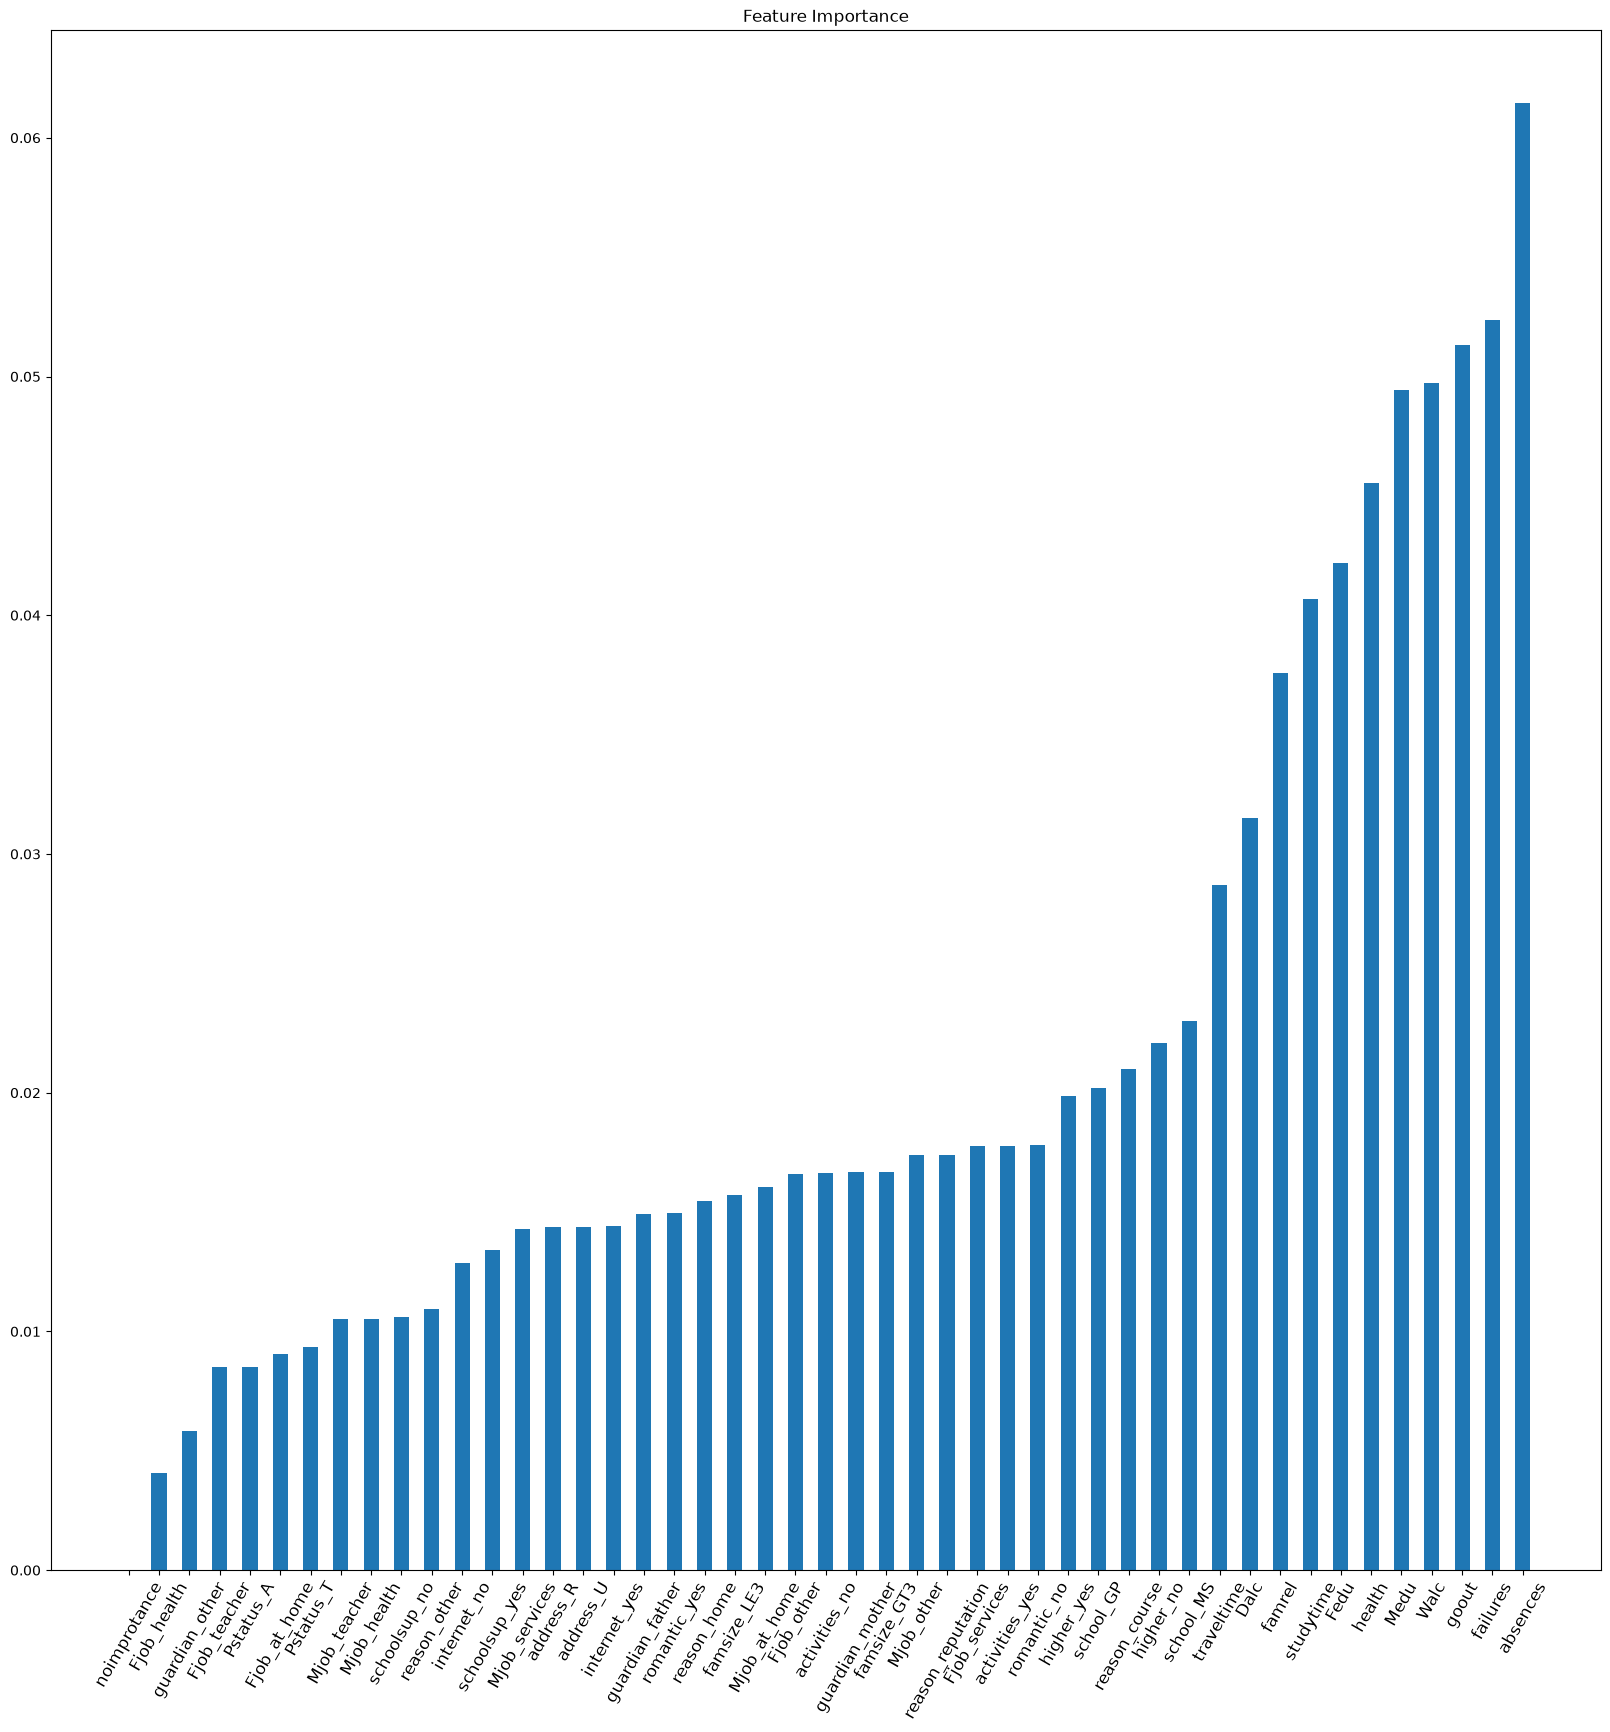

c:\Users\joche\anaconda3\envs\hcaid\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\joche\anaconda3\envs\hcaid\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\joche\anaconda3\envs\hcaid\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape

In [133]:
# =============================================================================
# #random forest
# =============================================================================
from sklearn.ensemble import RandomForestClassifier
classifier=RandomForestClassifier(n_estimators=80,criterion="entropy",random_state=0)
classifier.fit(X_train,y_train)

#predicting the test set re4sults
y_pred_random=classifier.predict(X_test)

importances=classifier.feature_importances_
for i,features in zip(importances,[ 'noimportant','Medu', 'Fedu', 'traveltime', 'datadytime', 'failures', 'famrel',
       'goout', 'Dalc', 'Walc', 'health', 'absences',
       'avg_grades', 'grades', 'school_GP', 'school_MS', 'address_R',
       'address_U', 'famsize_GT3', 'famsize_LE3', 'Pstatus_A', 'Pstatus_T',
       'Mjob_at_home', 'Mjob_health', 'Mjob_other', 'Mjob_services',
       'Mjob_teacher', 'Fjob_at_home', 'Fjob_health', 'Fjob_other',
       'Fjob_services', 'Fjob_teacher', 'reason_course', 'reason_home',
       'reason_other', 'reason_reputation', 'guardian_father',
       'guardian_mother', 'guardian_other', 'schoolsup_no', 'schoolsup_yes',
       'activities_no', 'activities_yes', 'higher_no', 'higher_yes',
       'internet_no', 'internet_yes', 'romantic_no', 'romantic_yes']):
    print("{}:{}".format(features,i))
indices = np.argsort(importances)

# Rearrange feature names so they match the sorted feature importances
names = [train_data2.columns[i] for i in indices]

# Barplot: Add bars

plt.figure(figsize=(20,20))
plt.bar(range(train_x.shape[1]), importances[indices],width=0.5)
# Add feature names as x-axis labels
plt.xticks(range(train_x.shape[1]),names, rotation=60, fontsize = 12)
#from here we cam see that absences is the important features for determining the grades of datadents

# Create plot title
plt.title("Feature Importance")
# Show plot
plt.show()

#determinnig the confusion matrix
from sklearn.metrics import confusion_matrix
cm_random=confusion_matrix(y_test,y_pred_random)

#determining the precision,recall and f1-score 
from sklearn.metrics import classification_report
report_random=classification_report(y_test,y_pred_random)


In [134]:
# =============================================================================
# # Fitting Kernel SVM to the Training set
# =============================================================================
from sklearn.svm import SVC
classifier = SVC(kernel = 'rbf', random_state = 0)
classifier.fit(X_train, y_train)
# Predicting the Test set results
y_pred_SVC= classifier.predict(X_test)
cm_SVC=confusion_matrix(y_test,y_pred_SVC)

#determining the precision,recall and f1-score 
from sklearn.metrics import classification_report
report_SVC=classification_report(y_test,y_pred_SVC)
print(report_SVC)

               precision    recall  f1-score   support

above average       0.00      0.00      0.00        20
      average       0.63      0.98      0.77        81
below average       0.60      0.13      0.21        23
         high       0.00      0.00      0.00         5
          low       0.00      0.00      0.00         1

     accuracy                           0.63       130
    macro avg       0.25      0.22      0.20       130
 weighted avg       0.50      0.63      0.52       130



c:\Users\joche\anaconda3\envs\hcaid\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\joche\anaconda3\envs\hcaid\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\joche\anaconda3\envs\hcaid\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape

In [135]:
# =============================================================================
# #fitting logistic regression to the training set
# =============================================================================
from sklearn.linear_model import LogisticRegression
classifier=LogisticRegression(random_state=0)
classifier.fit(X_train,y_train)
# Predicting the Test set results
y_pred_logistic= classifier.predict(X_test)

# Making the Confusion Matrix
from sklearn.metrics import confusion_matrix
cm_logistic= confusion_matrix(y_test, y_pred_logistic)

#determining the precision,recall and f1-score 
from sklearn.metrics import classification_report
report_logistic=classification_report(y_test,y_pred_logistic)

c:\Users\joche\anaconda3\envs\hcaid\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [136]:
# =============================================================================
# #fitting the knn_calssifier to the training set
# =============================================================================
from sklearn.neighbors import KNeighborsClassifier
classifier=KNeighborsClassifier(n_neighbors=5,metric='minkowski',p=2)
classifier.fit(X_train,y_train)
# Predicting the Test set results
y_pred_knn= classifier.predict(X_test)

# Making the Confusion Matrix
from sklearn.metrics import confusion_matrix
cm_knn= confusion_matrix(y_test, y_pred_knn)

#determining the precision,recall and f1-score 
from sklearn.metrics import classification_report
report_knn=classification_report(y_test,y_pred_knn)



c:\Users\joche\anaconda3\envs\hcaid\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\joche\anaconda3\envs\hcaid\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\joche\anaconda3\envs\hcaid\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape

In [137]:
print(report_random)
print(report_SVC)
print(report_logistic)
print(report_knn)

               precision    recall  f1-score   support

above average       0.40      0.10      0.16        20
      average       0.66      0.90      0.76        81
below average       0.50      0.30      0.38        23
         high       0.00      0.00      0.00         5
          low       0.00      0.00      0.00         1

     accuracy                           0.63       130
    macro avg       0.31      0.26      0.26       130
 weighted avg       0.56      0.63      0.57       130

               precision    recall  f1-score   support

above average       0.00      0.00      0.00        20
      average       0.63      0.98      0.77        81
below average       0.60      0.13      0.21        23
         high       0.00      0.00      0.00         5
          low       0.00      0.00      0.00         1

     accuracy                           0.63       130
    macro avg       0.25      0.22      0.20       130
 weighted avg       0.50      0.63      0.52       130

    

SO BY CONFUSION MATRIX AND F-SCORE WE FIND OUT THAT RANDOM FOREST IS BEST CLASSIFIER FOR GIVEN PROBLEM.

HERE WE PERFORM THE PREDITION IN A GOOD AND EVIL WAY

In [138]:
import numpy as np
import pandas as pd
import shap
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

# 1. Selecteer relevante features voor gedrag, achtergrond en cijfers
feature_cols = [
    "studytime",
    "failures",
    "absences",
    "freetime",
    "goout",
    "Dalc",
    "Walc",
    "health",
    "romantic",
    "higher",
    "schoolsup",
    "famsup",
    "internet",
    "Medu",
    "Fedu",
    "traveltime",
]

# One-hot encoding voor categorische kolommen
feature_cols = [col for col in feature_cols if col in data.columns]
X = pd.get_dummies(data[feature_cols], drop_first=True)
y = data["avg_grades"]

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 2. Model trainen
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# 3. SHAP Explainer initialiseren
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer(X_test)

print("Model getraind en SHAP-waarden succesvol berekend.")

Model getraind en SHAP-waarden succesvol berekend.


 🌟 STUDYCOMPANION: TRANSPARANT STUDIE-INZICHT
Verwacht gemiddeld cijfer: 13.4 / 20 (Bandbreedte: 12.3 - 14.5)

Toelichting totstandkoming van deze voorspelling (SHAP-analyse):
 ✓ Sterk punt: Je waarde voor 'failures' draagt positief bij (+0.62 pt).
 ⚠ Aandachtspunt: 'health' drukt je voorspelling momenteel (-0.19 pt).

Factoren met een SHAP-bijdrage van minstens 0.00 punt:
 - failures: +++ de voorspelling met 0.62 punt
 - studytime: +++ de voorspelling met 0.53 punt
 - health: --- de voorspelling met 0.19 punt
 - absences: +++ de voorspelling met 0.07 punt
 - goout: --- de voorspelling met 0.01 punt
 - freetime: +++ de voorspelling met 0.00 punt


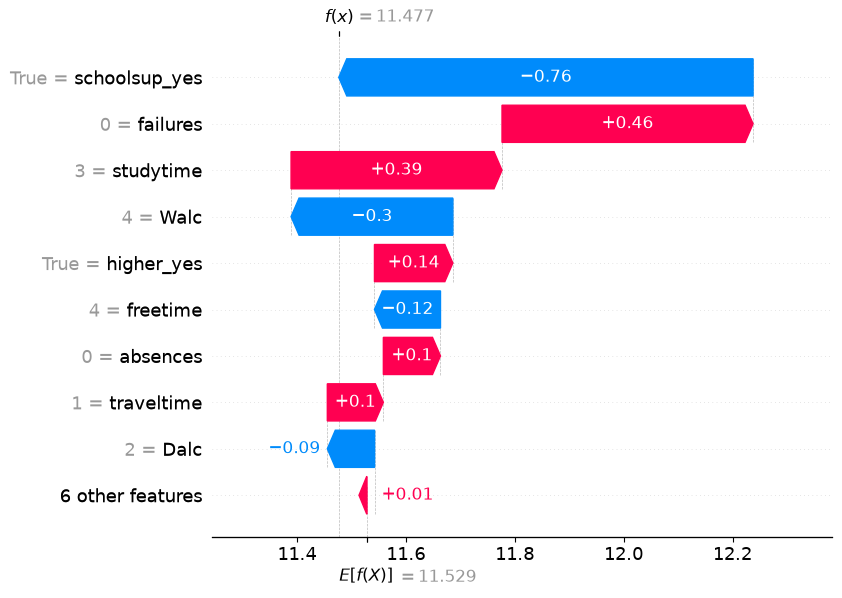

In [142]:
def good_ai_advisor(student_idx):
    student_row = X_test.iloc[[student_idx]]
    student_shap = shap_values[student_idx]
    predicted_grade = rf_model.predict(student_row)[0]

    # Bepaal onzekerheidsmarge (bijv. +/- 1 punt)
    lower_bound = max(0, predicted_grade - 1.1)
    upper_bound = min(20, predicted_grade + 1.1)

    print("=" * 55)
    print(" 🌟 STUDYCOMPANION: TRANSPARANT STUDIE-INZICHT")
    print("=" * 55)
    print(
        f"Verwacht gemiddeld cijfer: {predicted_grade:.1f} / 20 (Bandbreedte: {lower_bound:.1f} - {upper_bound:.1f})"
    )
    print(
        "\nToelichting totstandkoming van deze voorspelling (SHAP-analyse):"
    )

    # Filter op veranderbare gewoontes (geen ouders/achtergrond bekritiseren)
    actionable_features = [
        "studytime",
        "absences",
        "failures",
        "freetime",
        "goout",
        "health",
    ]

    contributions = []
    for feat, val in zip(student_shap.feature_names, student_shap.values):
        clean_feat = feat.split("_")[0]
        if clean_feat in actionable_features:
            contributions.append((feat, val))

    # Sorteer op impact
    contributions.sort(key=lambda x: x[1], reverse=True)

    positives = [c for c in contributions if c[1] > 0]
    negatives = [c for c in contributions if c[1] < 0]

    if positives:
        top_pos = positives[0]
        print(
            f" ✓ Sterk punt: Je waarde voor '{top_pos[0]}' draagt positief bij (+{top_pos[1]:.2f} pt)."
        )

    if negatives:
        top_neg = negatives[-1]
        print(
            f" ⚠ Aandachtspunt: '{top_neg[0]}' drukt je voorspelling momenteel (-{abs(top_neg[1]):.2f} pt)."
        )

    print("\nActiegericht advies:")
    current_study = student_row["studytime"].values[0]
    if current_study < 3:
        print(
            " -> Verhogen van wekelijkse studietijd met 1 niveau kan je cijfer naar verwachting met ~1.2 punt verhogen."
        )
    print(
        " -> Zorg voor voldoende slaap en ontspanning; welzijn staat voorop."
    )
    print("=" * 55)


# Testen voor de eerste student
def good_ai_advisor(student_idx):
    student_row = X_test.iloc[[student_idx]]
    student_shap = shap_values[student_idx]
    predicted_grade = rf_model.predict(student_row)[0]

    lower_bound = np.clip(predicted_grade - 1.1, 0, 20)
    upper_bound = np.clip(predicted_grade + 1.1, 0, 20)

    print("=" * 55)
    print(" 🌟 STUDYCOMPANION: TRANSPARANT STUDIE-INZICHT")
    print("=" * 55)
    print(
        f"Verwacht gemiddeld cijfer: {predicted_grade:.1f} / 20 "
        f"(Bandbreedte: {lower_bound:.1f} - {upper_bound:.1f})"
    )
    print("\nToelichting totstandkoming van deze voorspelling (SHAP-analyse):")

    actionable_features = [
        "studytime", "absences", "failures", "freetime", "goout", "health"
    ]

    contributions = []
    for feat, val in zip(student_shap.feature_names, student_shap.values):
        if feat.split("_")[0] in actionable_features:
            contributions.append((feat, val))

    contributions.sort(key=lambda x: x[1], reverse=True)
    positives = [c for c in contributions if c[1] > 0]
    negatives = [c for c in contributions if c[1] < 0]

    if positives:
        feat, value = positives[0]
        print(f" ✓ Sterk punt: Je waarde voor '{feat}' draagt positief bij (+{value:.2f} pt).")

    if negatives:
        feat, value = negatives[-1]
        print(f" ⚠ Aandachtspunt: '{feat}' drukt je voorspelling momenteel (-{abs(value):.2f} pt).")

        threshold = 0.0
        significant = [
            (feature, value)
            for feature, value in contributions
            if abs(value) >= threshold
        ]

        print(f"\nFactoren met een SHAP-bijdrage van minstens {threshold:.2f} punt:")
        if significant:
            for feature, value in sorted(significant, key=lambda item: abs(item[1]), reverse=True):
                direction = "+++" if value > 0 else "---"
                print(f" - {feature}: {direction} de voorspelling met {abs(value):.2f} punt")
        else:
            print(" - Geen veranderbare factoren halen deze drempel.")


good_ai_advisor(51)

# Force plot voor één student (interactieve HTML in notebook)
shap.initjs()
shap.force_plot(
    explainer.expected_value, shap_values.values[0], X_test.iloc[0]
)

# Waterfall plot (zeer geschikt voor de poster)
shap.plots.waterfall(shap_values[21])